In [4]:
import string
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle


df = pd.read_excel("../DATASET/Results/Ablation/save_model_channel/three_channel_ablation_full_metrics.xlsx")
df.head()

,Fold,Delay,Batchsize,LSTM,Dense,MAE,MSE,RMSE,Corr,P_Value,Threat_Score
0,0,4,12,10,100,76.238434,8902.390625,94.352478,0.150831,0.008882,0.04
1,0,4,12,10,200,76.985809,8901.706055,94.348854,0.165162,0.004125,0.04
2,0,4,12,10,300,76.515923,9250.491211,96.179474,0.189276,0.000986,0.00
3,0,4,12,10,400,76.471420,9273.691406,96.300011,0.188365,0.001044,0.00
4,0,4,12,10,500,76.922127,9245.314453,96.152557,0.198436,0.000546,0.08


In [2]:
print(f"The Maximum Correlation: {np.max(df['Corr'])}")
print(f"The Minimum Correlation: {np.min(df['Corr'])}")
print(f"The Maximum Threat Score: {np.max(df['Threat_Score'])}")
print(f"The Minimum Threat Score: {np.min(df['Threat_Score'])}")
threat_score_max_index = df['Threat_Score'].idxmax()
print(f"The Index of Maximum Threat Score: {threat_score_max_index}")

corr_max_index = df['Corr'].idxmax()
print(f"The Index of Maximum Correlation: {corr_max_index}")

lstm_position_at_max_threat_score = df.loc[threat_score_max_index, 'LSTM']
print(f"The LSTM Position at Maximum Threat Score: {lstm_position_at_max_threat_score}")

lstm_position_at_max_corr = df.loc[corr_max_index, 'LSTM']
print(f"The LSTM Position at Maximum Correlation: {lstm_position_at_max_corr}")

dense_position_at_max_threat_score = df.loc[threat_score_max_index, 'Dense']
print(f"The Dense Position at Maximum Threat Score: {dense_position_at_max_threat_score}")

dense_position_at_max_corr = df.loc[corr_max_index, 'Dense']
print(f"The Dense Position at Maximum Correlation: {dense_position_at_max_corr}")


The Maximum Correlation: 0.6595608474214175
The Minimum Correlation: -0.01150852235472707
The Maximum Threat Score: 0.5769230769230769
The Minimum Threat Score: 0.0
The Index of Maximum Threat Score: 623
The Index of Maximum Correlation: 620
The LSTM Position at Maximum Threat Score: 50
The LSTM Position at Maximum Correlation: 50
The Dense Position at Maximum Threat Score: 400
The Dense Position at Maximum Correlation: 100


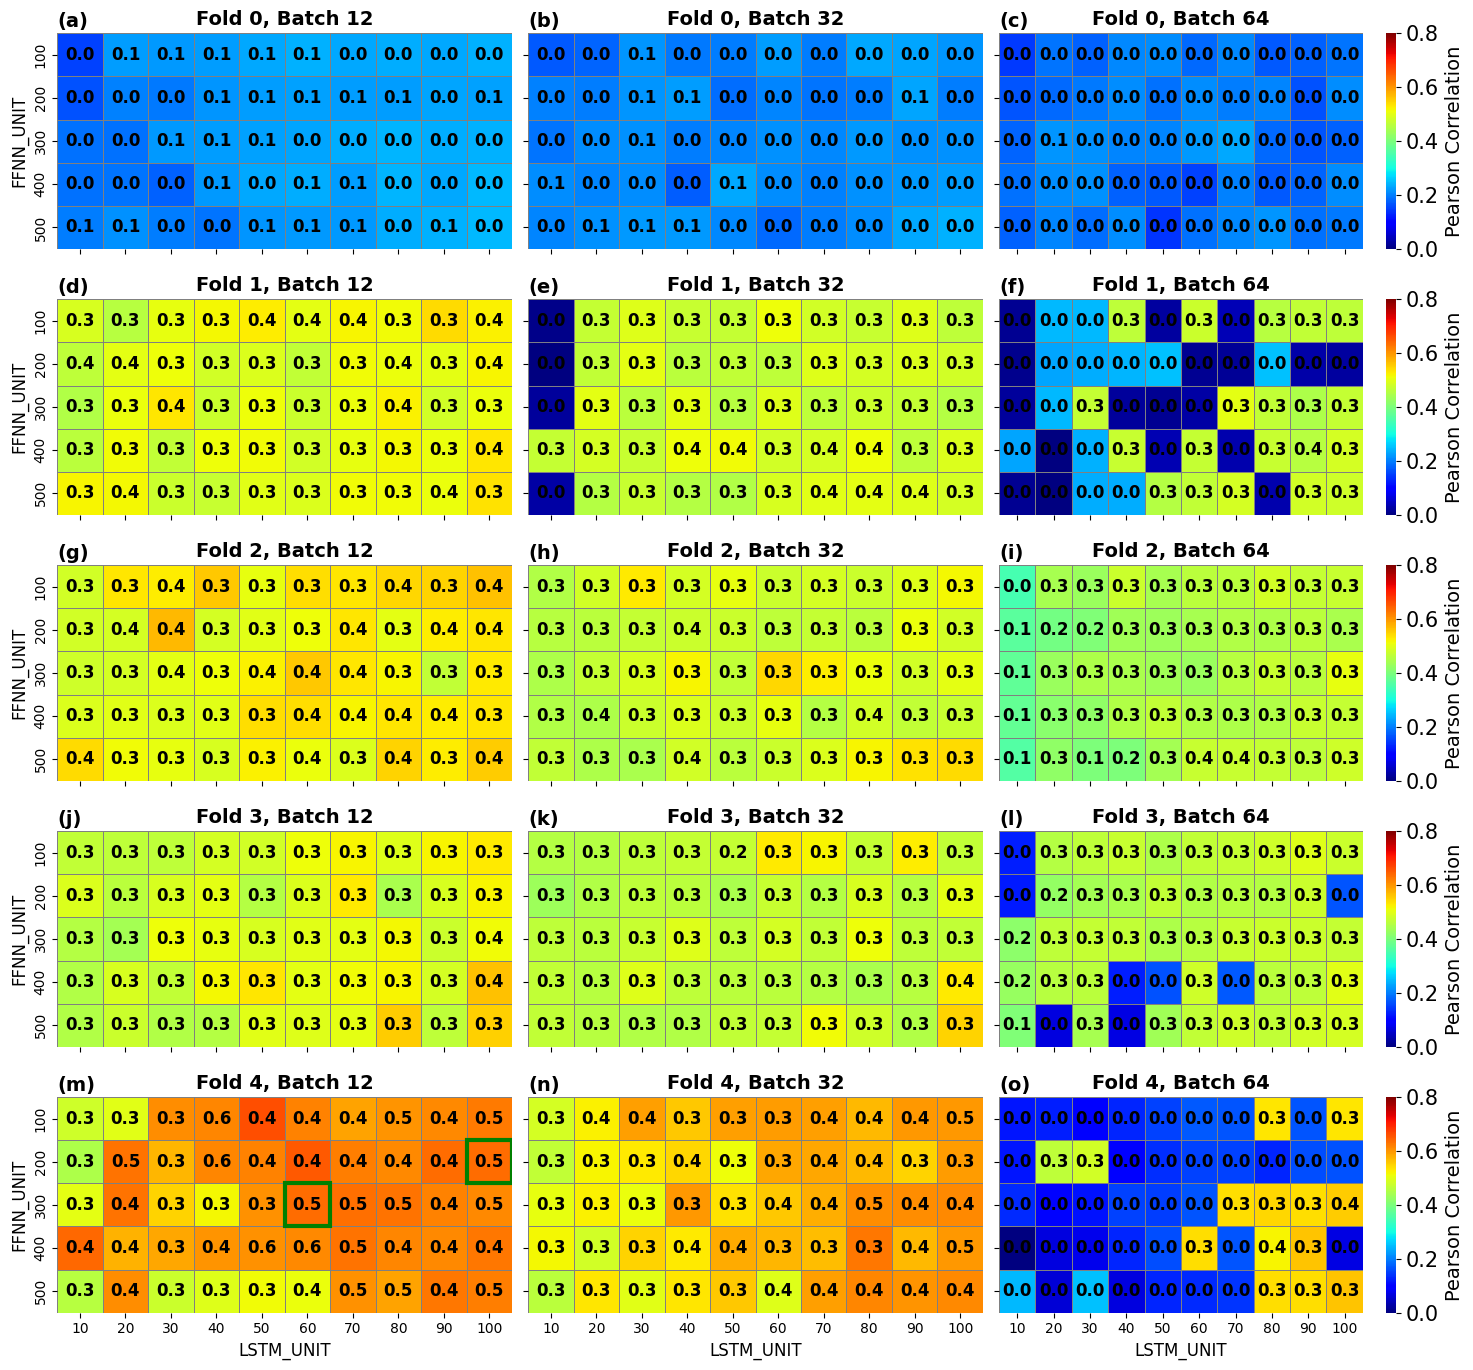

In [3]:
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15, 15))
labels = list(string.ascii_lowercase[:15])  # ['a', 'b', ..., 'o']
label_idx = 0

for i, fold in enumerate(sorted(df['Fold'].unique())):
    for j, batch in enumerate(sorted(df['Batchsize'].unique())):

        ax = axes[i, j]
        subset = df[(df['Fold'] == fold) & (df['Batchsize'] == batch)]

        # Pivot tables
        heatmap_data = subset.pivot(index='Dense', columns='LSTM', values='Corr')
        annot_data = subset.pivot(index='Dense', columns='LSTM', values='Threat_Score')

        show_cbar = (j == 2)
        heatmap = sns.heatmap(
            heatmap_data,
            annot=annot_data.round(1),
            fmt='',
            cmap='jet',
            cbar=show_cbar,
            ax=ax,
            linewidths=0.4,
            linecolor='gray',
            annot_kws={"size": 12, "color": "black", "weight": "bold"},
            vmin=0.0,
            vmax=0.8
        )

        if show_cbar:
            cbar = heatmap.collections[0].colorbar
            cbar.set_label("Pearson Correlation", fontsize=14)
            cbar.ax.tick_params(labelsize=15)

        # Subplot label
        ax.text(0, 1.1, f'({labels[label_idx]})', transform=ax.transAxes,
                fontsize=14, fontweight='bold', va='top', ha='left')
        label_idx += 1

        if j == 0:
            ax.set_ylabel("FFNN_UNIT", fontsize=12)
        else:
            ax.set_ylabel("")
            ax.set_yticklabels([])

        if i == 4:
            ax.set_xlabel("LSTM_UNIT", fontsize=12)
        else:
            ax.set_xlabel("")
            ax.set_xticklabels([])

        ax.tick_params(axis='both', labelsize=10)
        ax.set_title(f"Fold {fold}, Batch {batch}", fontsize=14, fontweight='semibold')

        
        for dense_val in heatmap_data.index:
            for lstm_val in heatmap_data.columns:
                corr_val = heatmap_data.loc[dense_val, lstm_val]
                threat_val = annot_data.loc[dense_val, lstm_val]

                if pd.notna(corr_val) and pd.notna(threat_val):
                    if corr_val >= 0.637 and threat_val >= 0.45:
                        row_idx = heatmap_data.index.get_loc(dense_val)
                        col_idx = heatmap_data.columns.get_loc(lstm_val)
                        rect = Rectangle(
                            (col_idx, row_idx), 1, 1,
                            fill=False, edgecolor='green', linewidth=3
                        )
                        ax.add_patch(rect)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig("../DATASET/Results/Ablation/Ablation_plot_and Eval_SpeedNet_EUV/Boxed_global_ablation_study_SpeedNet_EUV_conditional.png")
plt.savefig("../DATASET/Results/Ablation/Ablation_plot_and Eval_SpeedNet_EUV/Boxed_global_ablation_study_SpeedNet_EUV_conditional.pdf")
plt.show()
